# 🔵1) downloads and imports

### 🟠1.1) download stable-diffusion-2-base

In [4]:
# if needed 
#!pip install --upgrade diffusers transformers accelerate scipy safetensors

In [5]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


In [5]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# model name and location
model_id = "sd2-community/stable-diffusion-2-base"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")

# defining the base pipeline
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16 
)

# as in the other HW we have done, move it to cuda...
pipe = pipe.to("cuda")

# basic prompt to test
prompt = "A small dog, wearing sun glasses and mexican hat"

# running the prompt thru the pipe, and getting resaults
image = pipe(prompt).images[0]

#save and disply the image 
image.save("basic_stable_deffusion_check.png")
print("image saved as basic_stable_deffusion_check.png")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

image saved as basic_stable_deffusion_check.png


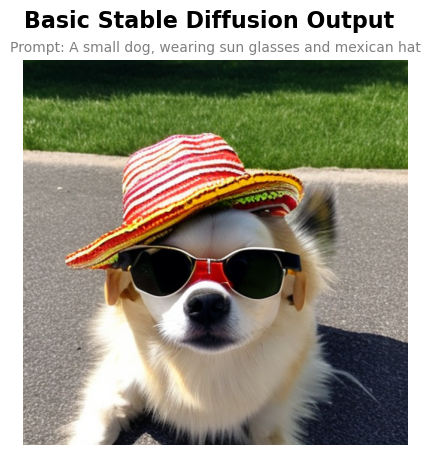

In [6]:
# show image generated
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread("basic_stable_deffusion_check.png")

plt.figure(figsize=(5, 5)) 

plt.imshow(img) 
plt.axis("off") 

plt.suptitle("Basic Stable Diffusion Output", fontsize=16, fontweight='bold')
plt.title("Prompt: A small dog, wearing sun glasses and mexican hat", fontsize=10, color='gray')

plt.show() 

# 🔵2) implementing the base denoising loop from scratch

In [12]:
import torch
import PIL
import numpy as np
from tqdm.auto import tqdm

def get_text_embeddings(pipe, prompt, negative_prompt, device):
    """
    Encodes the prompt and negative prompt into text embeddings.
    """
    text_input = pipe.tokenizer(
        prompt, 
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]

    uncond_input = pipe.tokenizer(
        negative_prompt,  
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    uncond_embeddings = pipe.text_encoder(uncond_input.input_ids.to(device))[0]

    text_embeddings = torch.cat([uncond_embeddings, text_embeddings])
    return text_embeddings


In [ ]:
def basic_text_to_image(pipe, prompt, negative_prompt="", seed=None, steps=50, guidance_scale=7.5, height=512, width=512):
    """
    Custom bare-bones loop for Text-to-Image generation.
    """
    device = pipe.device
    
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)

    # 1. Embed text
    text_embeddings = get_text_embeddings(pipe, prompt, negative_prompt, device)

    # 2. Initialize pure noise in the latent space
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    # Scale the initial noise by the scheduler's required standard deviation
    latents = latents * pipe.scheduler.init_noise_sigma
    
    # 3. Main Denoising Loop
    print("Running Denoising Loop...")
    for i, t in enumerate(tqdm(pipe.scheduler.timesteps)):
        
        # We duplicate the latents (x2) to run two parallel predictions in one batch 
        # (unconditional and conditional) for Classifier-Free Guidance.
        latent_model_input = torch.cat([latents] * 2)
        latent_model_input = pipe.scheduler.scale_model_input(latent_model_input, t)

        # Get the UNet prediction for the noise
        with torch.no_grad():
            noise_pred = pipe.unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

        # Split the prediction back into unconditional and conditional
        noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)

        # Apply the Guidance formula
        noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

        # Subtract the predicted noise from the latents
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample
    
    # 4. Final decode from latent space to image space using the VAE
    with torch.no_grad():
        latents = 1 / 0.18215 * latents
        image = pipe.vae.decode(latents).sample

    # 5. Format to PIL Image
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Running Denoising Loop...


  0%|          | 0/50 [00:00<?, ?it/s]

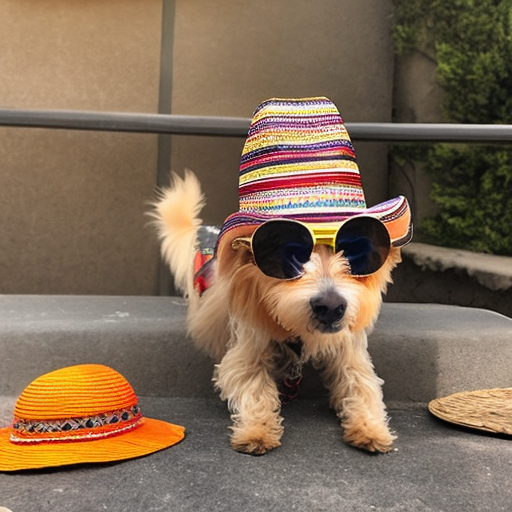

In [19]:
model_id = "sd2-community/stable-diffusion-2-base"
device = "cuda" if torch.cuda.is_available() else "cpu"

scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")
pipe = StableDiffusionPipeline.from_pretrained(
    model_id, 
    scheduler=scheduler, 
    torch_dtype=torch.float16
).to(device)

prompt = "A small dog, wearing sun glasses and mexican hat"
image = basic_text_to_image(pipe, prompt, seed=42)

display(image)

Generating WITHOUT CFG...


Denoising (No CFG):   0%|          | 0/50 [00:00<?, ?it/s]

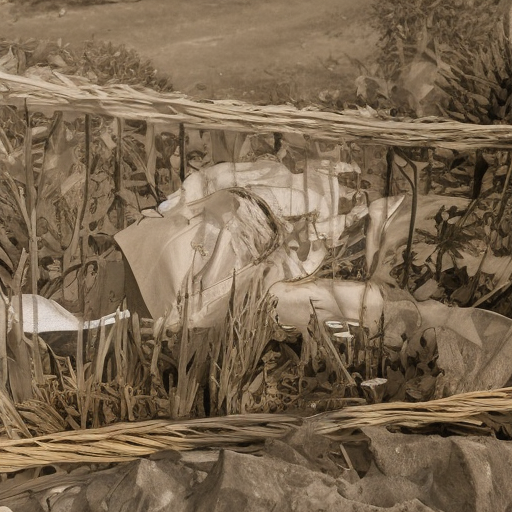

In [17]:
import torch
import PIL
import numpy as np
from tqdm.auto import tqdm
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler
from IPython.display import display

def no_cfg_text_to_image(pipe, prompt, seed=None, steps=50, height=512, width=512):
    device = pipe.device
    
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)
    else:
        generator = torch.Generator(device=device)

    # 1. Embed ONLY the positive text (No negative prompt, no concatenation)
    text_input = pipe.tokenizer(
        prompt, 
        padding="max_length", 
        max_length=pipe.tokenizer.model_max_length, 
        truncation=True, 
        return_tensors="pt"
    )
    text_embeddings = pipe.text_encoder(text_input.input_ids.to(device))[0]

    # 2. Initialize noise
    pipe.scheduler.set_timesteps(steps)
    latents = torch.randn(
        (1, 4, height // 8, width // 8), 
        generator=generator, 
        device=device, 
        dtype=torch.float16
    )
    latents = latents * pipe.scheduler.init_noise_sigma
    
    # 3. Denoising Loop WITHOUT CFG
    for i, t in enumerate(tqdm(pipe.scheduler.timesteps, desc="Denoising (No CFG)")):
        
        # No duplication! We just pass the single latent tensor.
        latent_model_input = pipe.scheduler.scale_model_input(latents, t)

        # Get the UNet prediction based ONLY on the text
        with torch.no_grad():
            noise_pred = pipe.unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

        # NO splitting, NO guidance formula. 
        # We just take the raw prediction and step forward.
        latents = pipe.scheduler.step(noise_pred, t, latents).prev_sample
    
    # 4. Decode
    with torch.no_grad():
        latents = 1 / 0.18215 * latents
        image = pipe.vae.decode(latents).sample

    # 5. Format
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).float().numpy()
    final_image = PIL.Image.fromarray((image[0] * 255).round().astype("uint8"))
    
    return final_image

# (בהנחה שהמודל כבר נטען לזיכרון תחת המשתנה pipe מהבלוק הקודם)

# הרצת יצירת התמונה ללא CFG
prompt = "A small dog, wearing sun glasses and mexican hat"
print("Generating WITHOUT CFG...")
image_no_cfg = no_cfg_text_to_image(pipe, prompt, seed=42) # השתמשנו באותו seed להשוואה הוגנת

display(image_no_cfg)